In [1]:
%env OPENBLAS_NUM_THREADS=1
%env OMP_NUM_THREADS=1
%env MKL_NUM_THREADS=1
%env NUMEXPR_NUM_THREADS=1
%env BLIS_NUM_THREADS=1
%env VECLIB_MAXIMUM_THREADS=1

env: OPENBLAS_NUM_THREADS=1
env: OMP_NUM_THREADS=1
env: MKL_NUM_THREADS=1
env: NUMEXPR_NUM_THREADS=1
env: BLIS_NUM_THREADS=1
env: VECLIB_MAXIMUM_THREADS=1


In [66]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl
import seaborn as sns
import gseapy as gp
from tqdm.auto import tqdm

In [161]:
perturbation_colors = {
    "NT": "#555555",        # dark gray
    "RUBY": "#cccccc",      # light gray
    "MOCK": "#000000",      # black
    "FBL": "#1f77b4",       # blue
    "FTL": "#ff7f0e",       # orange
    "MALAT": "#2ca02c",     # green
    "NEAT": "#d62728",      # red
    "SNHG15": "#9467bd",    # purple
    "SNHG16": "#8c564b",    # brown
    "VIM": "#e377c2",       # pink
    "LINC": "#17becf",      # teal
    "PPIA_T1": "#bcbd22",   # olive
}


In [3]:
DIR = Path("/g/huber/users/peidli/data/SYMPHONY/SYM10RNAseq")

In [ ]:
sample_list = list(pd.read_csv("../resources/sample_list.txt", index_col=0, header=None).index)

In [5]:
tabs = {}
for sample in tqdm(sample_list):
    d = DIR / f'{sample}/RNA/counts/'
    if d.exists():
        tab = pd.read_csv(d / f"{sample}.converted_counts.tsv.gz", compression='gzip', sep='\t', header=0, skiprows=6, index_col=(0,1,2,3,4))
        tabs[sample] = tab['count']


  0%|          | 0/345 [00:00<?, ?it/s]

In [6]:
df = pd.concat(tabs, axis=1)
df = df[~df.index.get_level_values(1).duplicated(keep='first')]

In [7]:
df

,,,,,75CAS_FBL_V1_R1,75CAS_FBL_V1_R2,75CAS_FBL_V1_R3,75CAS_FBL_V2_R1,75CAS_FBL_V2_R2,75CAS_FBL_V2_R3,75CAS_FBL_V3_R1,75CAS_FBL_V3_R2,75CAS_FBL_V3_R3,75CAS_FTL_V1_R1,...,99CAS_SNHG16_V2_R3,99CAS_VIM_V1_R1,99CAS_VIM_V1_R2,99CAS_VIM_V1_R3,99CAS_VIM_V2_R1,99CAS_VIM_V2_R2,99CAS_VIM_V2_R3,99CAS_VIM_V3_R1,99CAS_VIM_V3_R2,99CAS_VIM_V3_R3
#ensid,gene,biotype,chr,longest_isoform,,,,,,,,,,,,,,,,,,,,,
ENSG00000000003,TSPAN6,protein_coding,X,3796,765,661,725,736,725,558,681,656,726,740,...,512,1388,1192,994,1049,1064,1065,1465,1480,1385
ENSG00000000005,TNMD,protein_coding,X,1205,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ENSG00000000419,DPM1,protein_coding,20,1161,1052,864,1047,1035,934,817,1026,1020,1058,738,...,672,1005,838,695,805,800,837,944,955,809
ENSG00000000457,SCYL3,protein_coding,1,6308,202,185,239,246,194,206,230,205,238,221,...,124,169,161,149,194,152,168,184,213,167
ENSG00000000460,C1orf112,protein_coding,1,4355,476,358,447,477,421,390,462,413,454,356,...,321,562,548,415,441,404,479,415,447,358
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERCC-00164,ERCC-00164,unknown,ERCC-00164,1022,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ERCC-00165,ERCC-00165,unknown,ERCC-00165,872,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ERCC-00168,ERCC-00168,unknown,ERCC-00168,1024,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
df.to_csv(DIR / "prelim_combined_counts.tsv", sep='\t', header=True)

In [114]:
df = pd.read_csv(DIR / "prelim_combined_counts.tsv", sep='\t', header=0, index_col=(0,1,2,3,4))

In [115]:
line = ['H1299' if k=='99' else 'H1975' if k=='75' else 'Unknown' for k in df.columns.str[:2]]  # TODO: verify this!
genotype = list(df.columns.str.split('_').str[0].str[2:])
perturbation = list(df.columns.str.split('_').str[1])
guide = list(df.columns.str.split('_').str[2])  # TODO: verify this!
replicate = list(df.columns.str.split('_').str[3])  # TODO: verify this!

In [137]:
# coldata = pd.DataFrame({
#  "line": line,
#  "genotype": genotype,
#  "perturbation": perturbation,
#  "guide": guide,
#  "replicate": replicate
# }, index=df.columns)
# # Cleanup
# for index, row in coldata[~coldata.index.str.contains('_V')].iterrows():
#     coldata.loc[index, 'guide'] = row.perturbation[-1] if 'MOCK' not in index else None
#     coldata.loc[index, 'perturbation'] = row.perturbation[:-1].upper() if 'MOCK' not in index else 'MOCK'
#     coldata.loc[index, 'replicate'] = row.guide
# coldata.to_csv(DIR / "prelim_combined_coldata.tsv", sep='\t', header=True)
coldata = pd.read_csv(DIR / "prelim_combined_coldata.tsv", sep='\t', header=0, index_col=0)

In [138]:
coldata

,line,genotype,perturbation,guide,replicate
75CAS_FBL_V1_R1,H1975,CAS,FBL,V1,R1
75CAS_FBL_V1_R2,H1975,CAS,FBL,V1,R2
75CAS_FBL_V1_R3,H1975,CAS,FBL,V1,R3
75CAS_FBL_V2_R1,H1975,CAS,FBL,V2,R1
75CAS_FBL_V2_R2,H1975,CAS,FBL,V2,R2
...,...,...,...,...,...
99CAS_VIM_V2_R2,H1299,CAS,VIM,V2,R2
99CAS_VIM_V2_R3,H1299,CAS,VIM,V2,R3
99CAS_VIM_V3_R1,H1299,CAS,VIM,V3,R1
99CAS_VIM_V3_R2,H1299,CAS,VIM,V3,R2


In [145]:
df_vst = pd.read_csv(DIR / "vsd_counts.csv", header=0, index_col=0)

/home/peidli/miniconda3/envs/sc_env/lib/python3.9/site-packages/PyComplexHeatmap/clustermap.py:835: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/peidli/miniconda3/envs/sc_env/lib/python3.9/site-packages/PyComplexHeatmap/clustermap.py:835: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


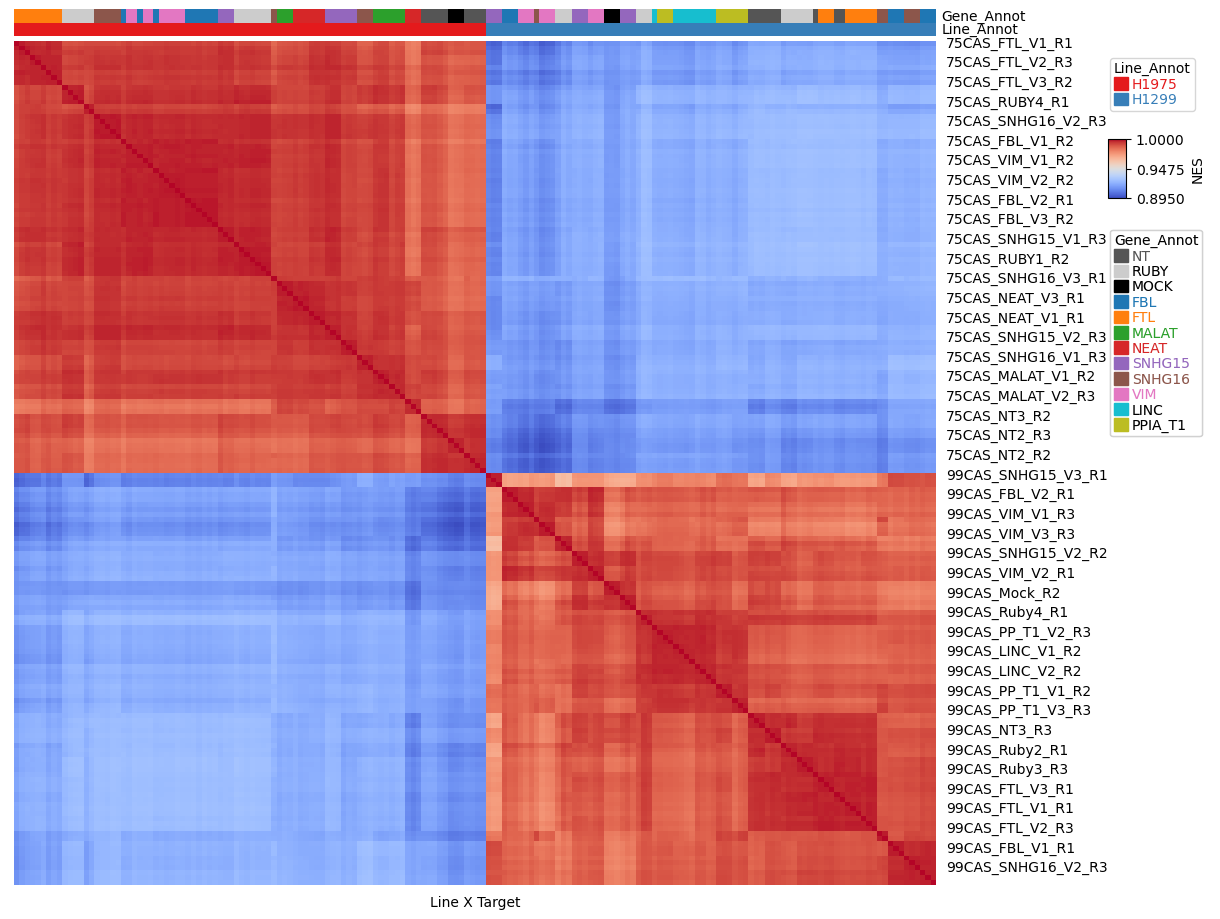

In [164]:
import PyComplexHeatmap as pch
corr = df_vst.corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(coldata.perturbation, add_text=False, colors=perturbation_colors),
    Line_Annot=pch.anno_simple(coldata.line, add_text=False),
    # Guide_Annot=pch.anno_simple(coldata.guide, add_text=False),
    # Replicate_Annot=pch.anno_simple(coldata.replicate, add_text=False),
    axis=1, verbose=0,
)

# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=True,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    # left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Line X Target", label='NES',
)

/home/peidli/miniconda3/envs/sc_env/lib/python3.9/site-packages/PyComplexHeatmap/clustermap.py:835: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/peidli/miniconda3/envs/sc_env/lib/python3.9/site-packages/PyComplexHeatmap/clustermap.py:835: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


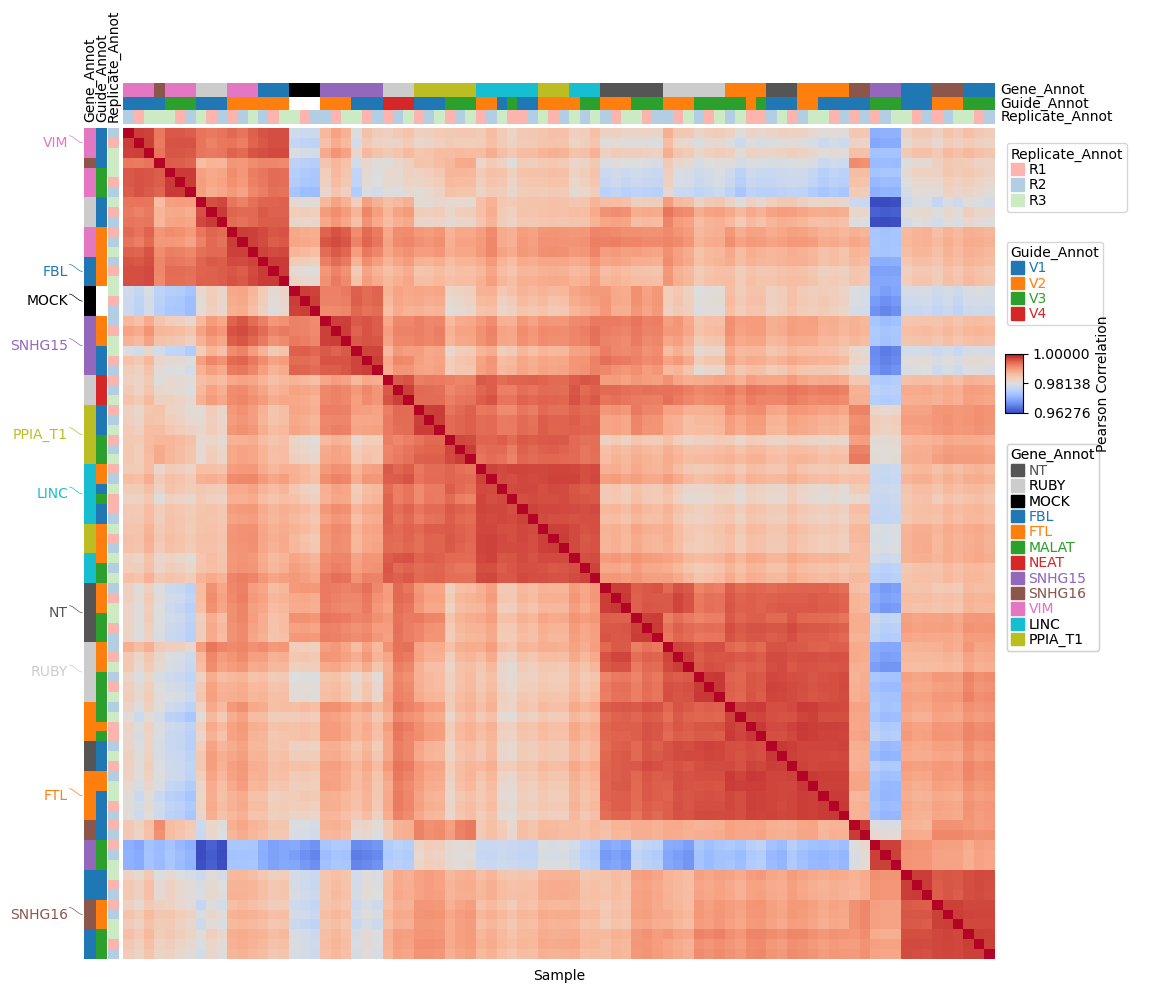

In [165]:
import PyComplexHeatmap as pch

scolData = coldata[coldata.line == 'H1299']
corr = df_vst[scolData.index].corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=1, verbose=0,
)
row_annotations = pch.HeatmapAnnotation(
    Gene_Label=pch.anno_label(scolData.perturbation, merge=True, colors=perturbation_colors),
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=0, verbose=0,
)
# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=False,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Sample", label='Pearson Correlation',
)

/home/peidli/miniconda3/envs/sc_env/lib/python3.9/site-packages/PyComplexHeatmap/clustermap.py:835: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/peidli/miniconda3/envs/sc_env/lib/python3.9/site-packages/PyComplexHeatmap/clustermap.py:835: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


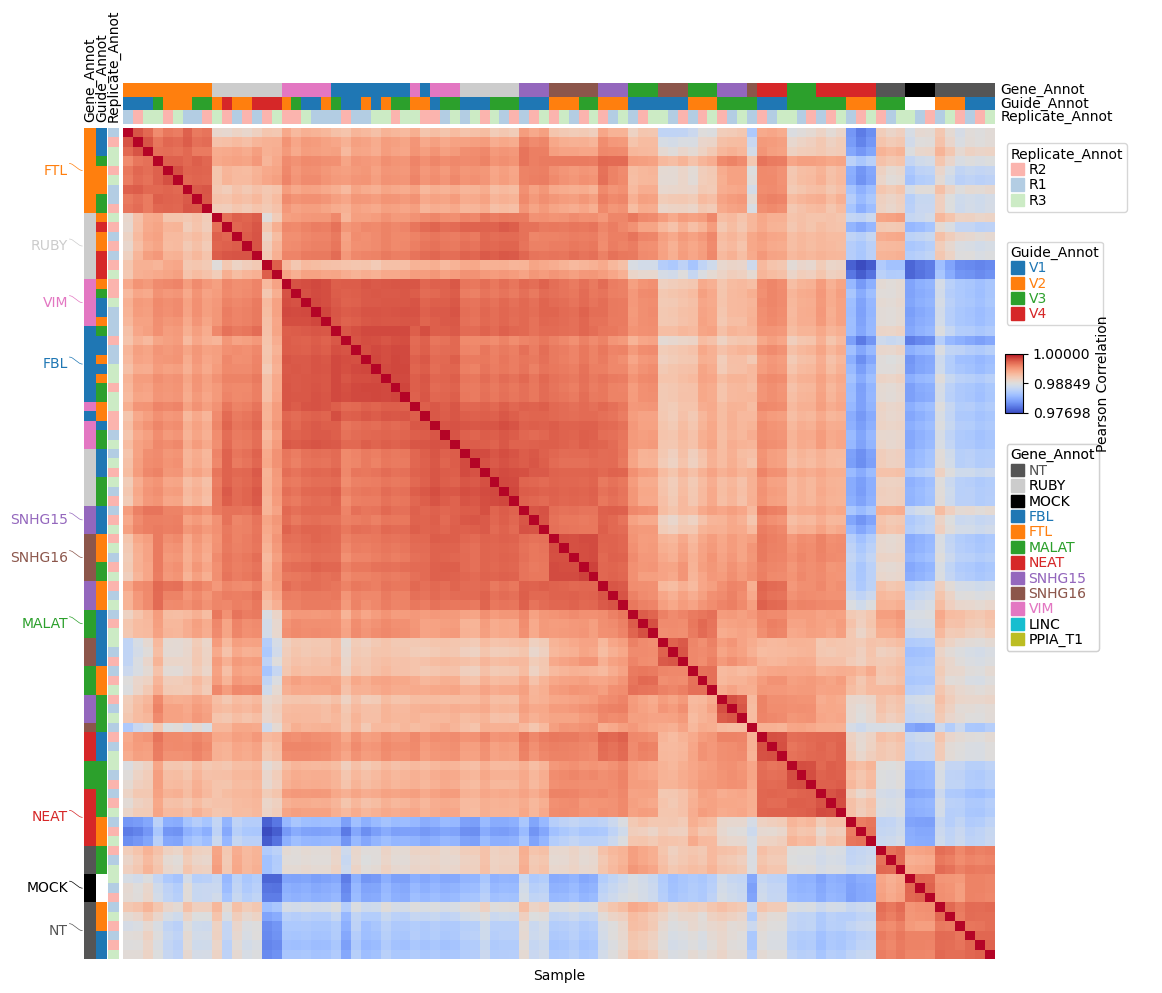

In [166]:
import PyComplexHeatmap as pch

scolData = coldata[coldata.line == 'H1975']
corr = df_vst[scolData.index].corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=1, verbose=0,
)
row_annotations = pch.HeatmapAnnotation(
    Gene_Label=pch.anno_label(scolData.perturbation, merge=True, colors=perturbation_colors),
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=0, verbose=0,
)
# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=False,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Sample", label='Pearson Correlation',
)

,PC1,PC2,line,genotype,perturbation,guide,replicate
75CAS_MOCK_R1,-159.252611,112.072755,H1975,CAS,MOCK,NaN,R1
75CAS_MOCK_R2,-153.059205,112.507548,H1975,CAS,MOCK,NaN,R2
75CAS_MOCK_R3,-166.909397,102.059255,H1975,CAS,MOCK,NaN,R3


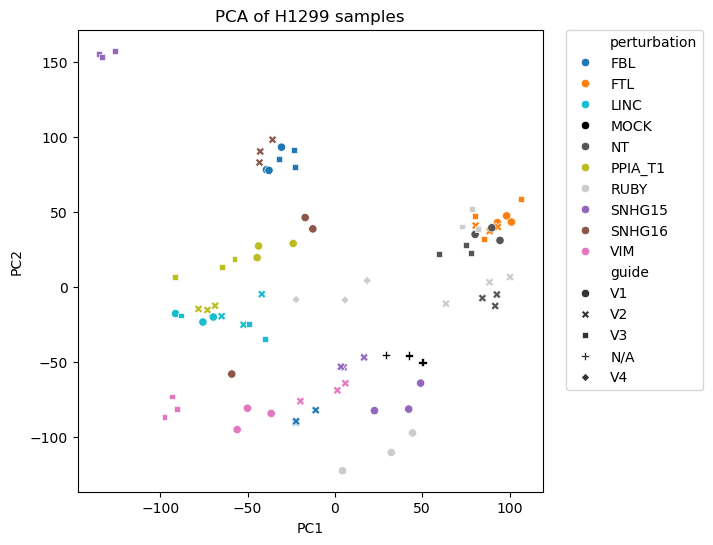

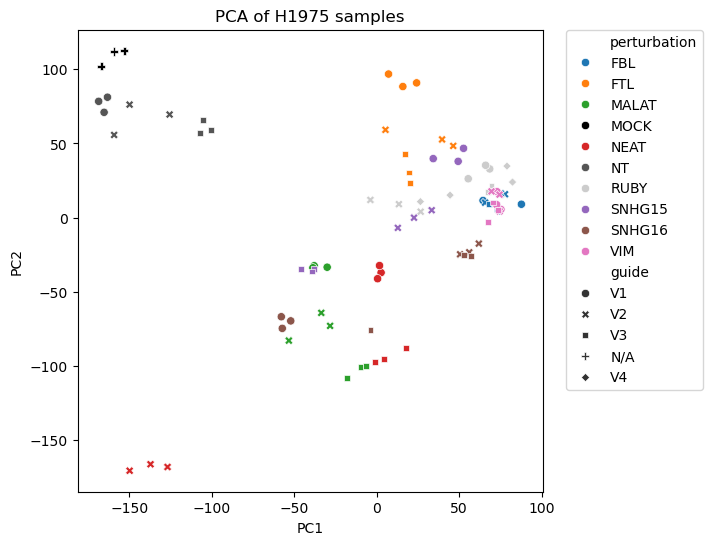

In [180]:
# PCA plot
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

for line in ['H1299', 'H1975']:
    scolData = coldata[coldata.line == line]
    embedding = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(df_vst[scolData.index].T))
    pca_df = pd.DataFrame(embedding, columns=['PC1', 'PC2'], index=scolData.index).join(scolData)
    pca_df.loc[pca_df.perturbation=='MOCK', 'guide'] = 'N/A'  # Otherwise there is no plots made for MOCK
    fig, ax = pl.subplots(figsize=(6, 6))
    sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='perturbation', style='guide', palette=perturbation_colors, ax=ax)
    ax.set_title(f'PCA of {line} samples')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    pl.show()

# Vis Deseq2 results

In [8]:
results_folder = DIR / "deseq2_results"

In [64]:
res = {}
for file in results_folder.glob("*.csv"):
    gene = file.stem.split("_")[0]
    # Correct names
    gene = 'MOCK' if gene == 'MOC' else gene
    gene = 'MALAT1' if gene == 'MALAT' else gene
    gene = 'NEAT1' if gene == 'NEAT' else gene
    gene = 'LINC-PINT' if gene == 'LINC' else gene
    gene = 'PPIA' if gene == 'PP' else gene
    df = pd.read_csv(file, index_col=0)
    res[gene] = df
tab = pd.concat(res, axis=1)

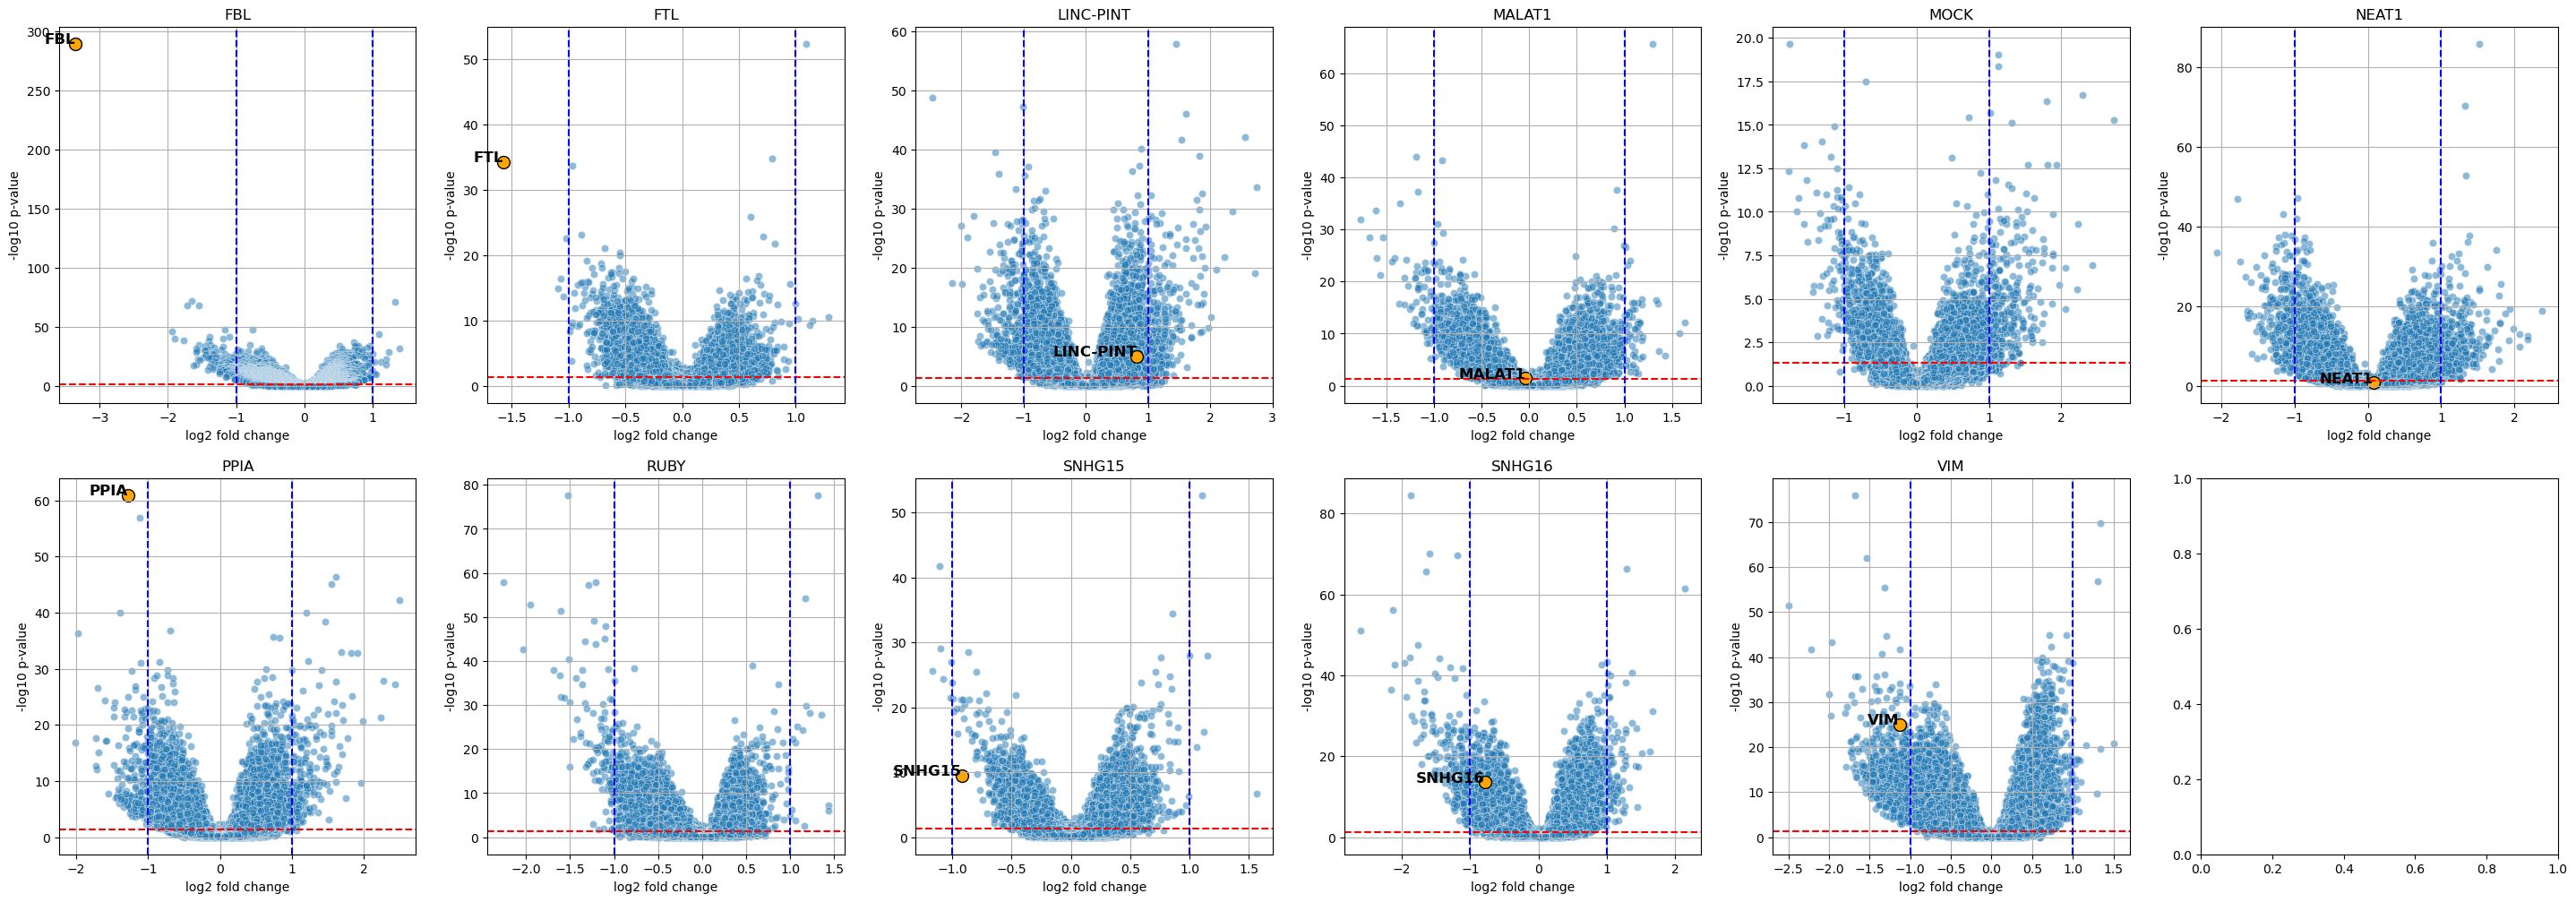

In [65]:
# Vulcano plot per target gene
genes = list(tab.columns.get_level_values(0).unique())
nrows = 2
ncols = int(np.ceil(len(genes)/nrows))
fig, axs = pl.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))
for ax, gene in zip(axs.flat, genes):
    df = tab[gene]
    sns.scatterplot(data=df, x='log2FoldChange', y=-np.log10(df['pvalue']), alpha=0.5, ax=ax)
    ax.set_title(gene)
    ax.set_xlabel('log2 fold change')
    ax.set_ylabel('-log10 p-value')
    ax.axhline(-np.log10(0.05), color='red', linestyle='--')
    ax.axvline(1, color='blue', linestyle='--')
    ax.axvline(-1, color='blue', linestyle='--')
    ax.grid(True)
    # Mark target gene
    if gene in df.index:
        target_df = df.loc[gene]
        ax.scatter(target_df['log2FoldChange'], -np.log10(target_df['pvalue']), color='orange', s=100, edgecolor='black')
        ax.text(target_df['log2FoldChange'], -np.log10(target_df['pvalue']), gene, fontsize=12, weight='bold', ha='right')
pl.show()

# GSEA

In [ ]:
# For each perturbation and cell line, use the DEGs from Wilcoxon rank-sum test
# We accept that the resulting gene lists are heavily enriched with FDR genes,
# since we just want to run GSEA on top of it.
results = {}
genes = list(tab.index.get_level_values(1).unique())
# for cell_line in tqdm(cell_lines):
for gene in genes:
    df = sig_degs[(sig_degs['cell_line'] == cell_line) & (sig_degs['target'] == target)]
    df.sort_values('scores', inplace=True)
    pre_res = gp.prerank(rnk=df[['gene', 'scores']],
                    gene_sets='MSigDB_Hallmark_2020,KEGG_2021_Human',
                    threads=4,
                    min_size=5,
                    max_size=1000,
                    permutation_num=100,
                    outdir=None, # don't write to disk
                    seed=42,
                    verbose=False,
                    no_plot=True,
                )
    results[(cell_line, target)] = pre_res.res2d

,index,score
0,Z98257.1,-71.539084
1,RBBP8NL,-57.979242
2,ANKRD33,-51.741569
3,KRT16P2,-47.780443
4,ALDH3B2,-41.164263
...,...,...
15808,COQ10B,38.964231
15809,ZMPSTE24,41.408323
15810,PPP2CA,41.408323
15811,CLCN4,53.034623


In [93]:
gsea_results = {}
for gene in tqdm(genes):
    df = tab.loc[:, gene]
    df = df[(df.baseMean > 10) & (~df.padj.isna())]
    df['score'] = -np.log10(df.padj) * np.sign(df.log2FoldChange)
    df.sort_values('score', inplace=True)

    pre_res = gp.prerank(rnk=df.reset_index()[['index', 'score']],
                        gene_sets='MSigDB_Hallmark_2020',#,KEGG_2021_Human',
                        threads=4,
                        min_size=5,
                        max_size=1000,
                        permutation_num=100,
                        outdir=None, # don't write to disk
                        seed=42,
                        verbose=False,
                        no_plot=True,
                    )
    gsea_results[gene] = pre_res.res2d

  0%|          | 0/11 [00:00<?, ?it/s]

2025-09-04 12:35:09,230 [WARNING] Duplicated values found in preranked stats: 7.14% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:09,644 [WARNING] Duplicated values found in preranked stats: 12.08% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:10,055 [WARNING] Duplicated values found in preranked stats: 8.06% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:10,500 [WARNING] Duplicated values found in preranked stats: 9.65% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:10,910 [WARNING] Duplicated values found in preranked stats: 24.87% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:11,344 [WARNING] Duplicated values found in preranked stats: 7.15% of genes
The order of those genes will 

/tmp/ipykernel_3307781/1057318274.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res_df.sort_values('NES', ascending=False, inplace=True)
/tmp/ipykernel_3307781/1057318274.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res_df.sort_values('NES', ascending=False, inplace=True)
/tmp/ipykernel_3307781/1057318274.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res_df.sort_values('NES', ascending=False, inplace=True)
/tmp/ipyke

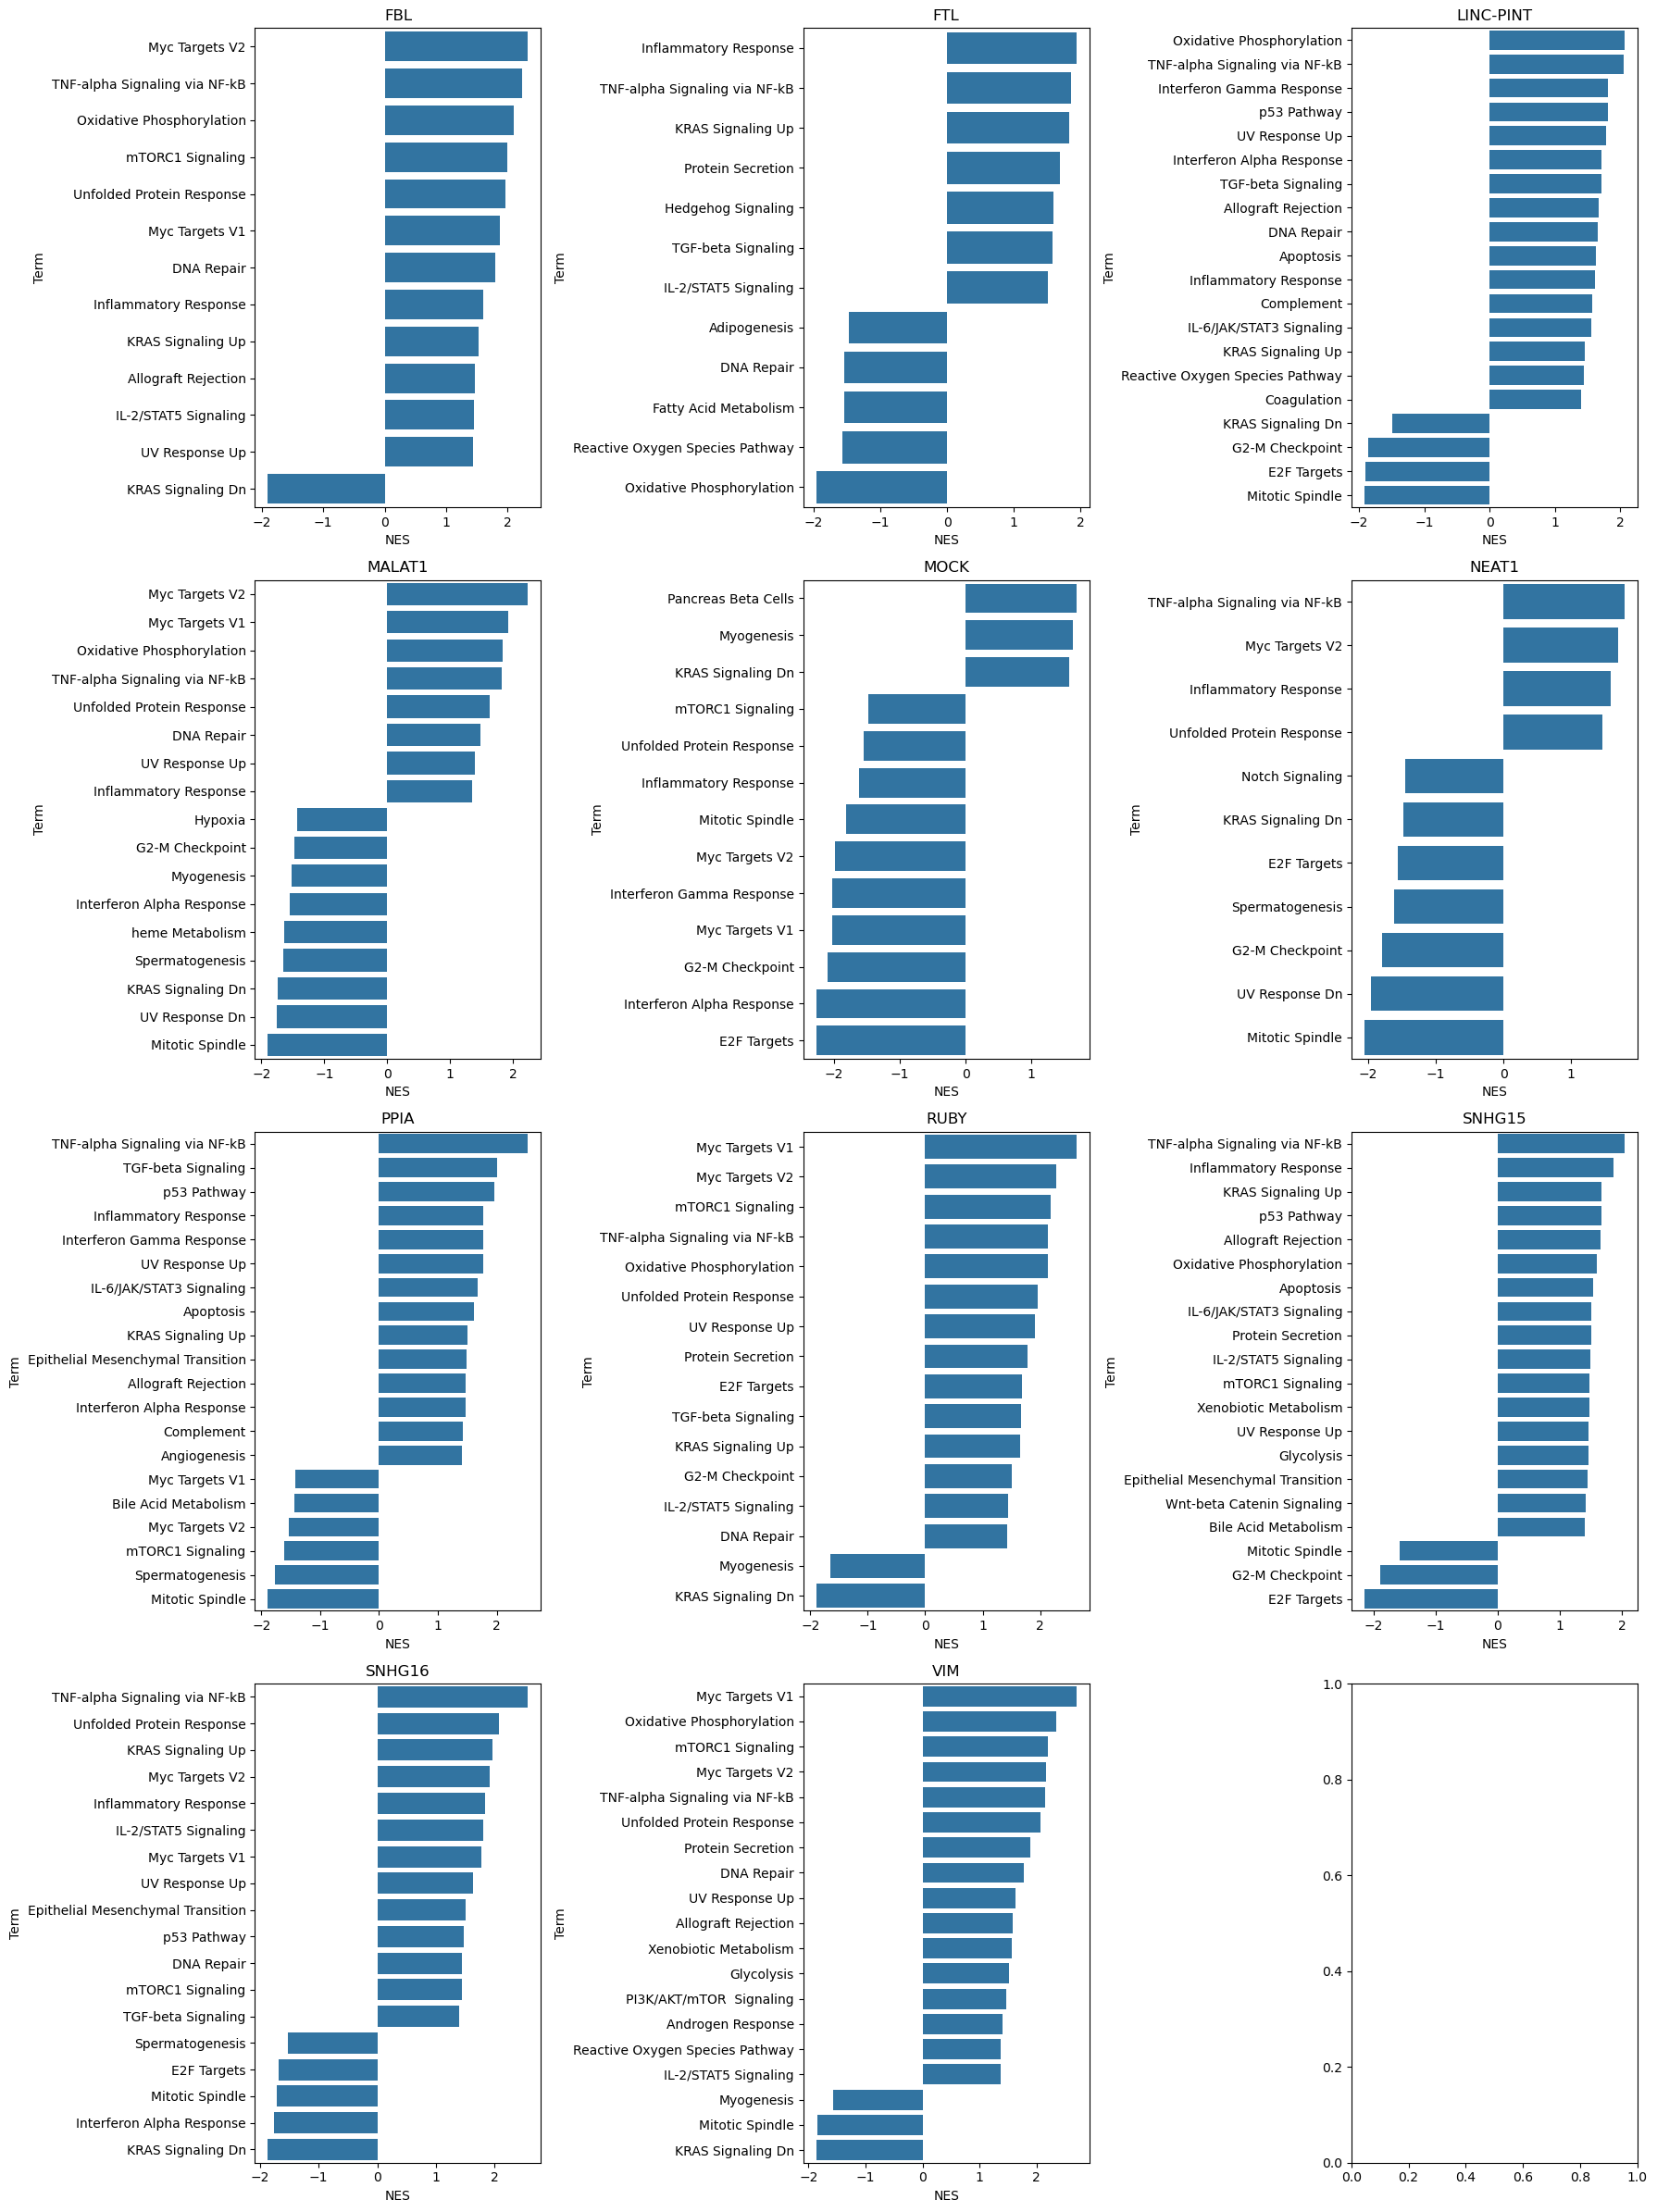

In [98]:
nrows = 4
ncols = int(np.ceil(len(genes)/nrows))
fig, axs = pl.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))
for gene, ax in zip(genes, axs.flat):
    res_df = gsea_results[gene]
    res_df = res_df[res_df['FDR q-val'] < 0.05]
    res_df.sort_values('NES', ascending=False, inplace=True)
    sns.barplot(data=res_df.head(20), y='Term', x='NES', ax=ax)
    ax.set_title(gene)
pl.tight_layout()
pl.show()

In [107]:
mat = pd.concat(gsea_results, axis=0).reset_index(level=0, names='gene').pivot(index='Term', columns='gene', values='NES')
mat = mat.astype(float)

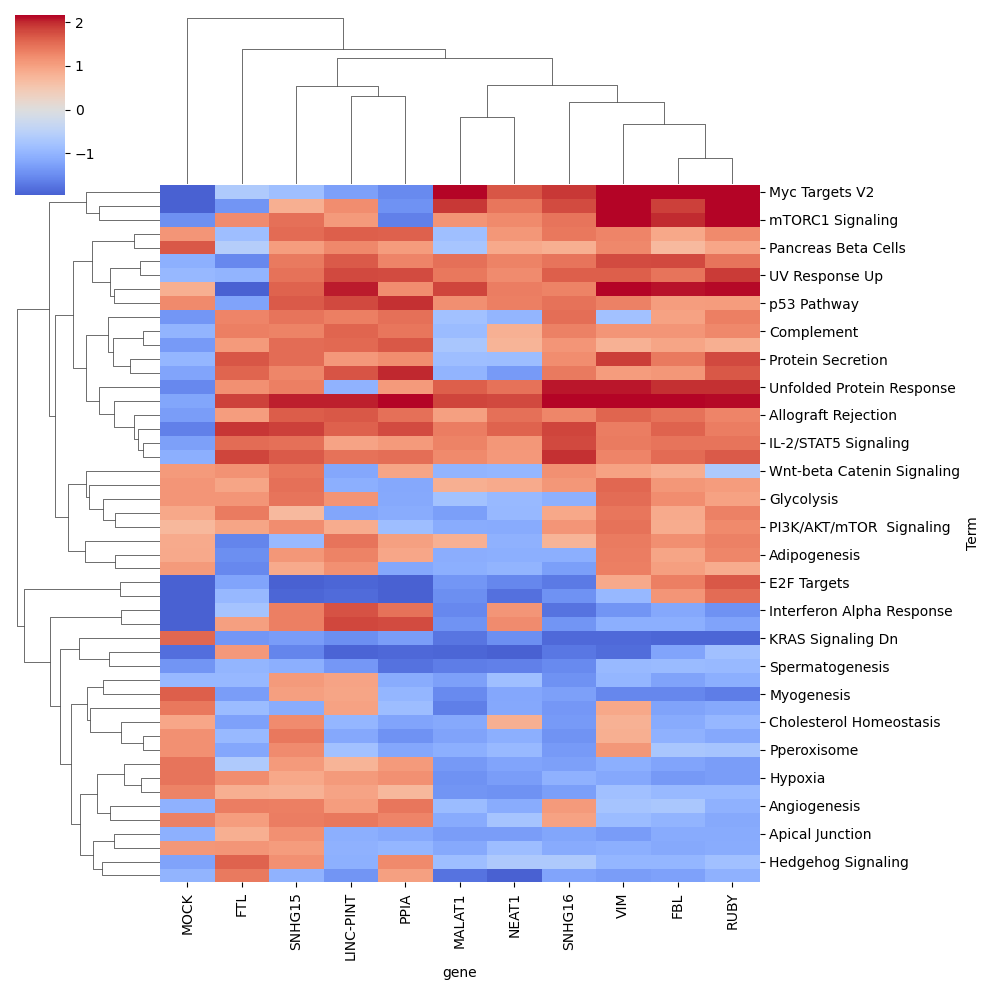

In [113]:
sns.clustermap(mat, cmap='coolwarm', center=0, robust=True)